In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm


def generate_symmetric_matrix(n: int) -> np.ndarray:
    """
    Generate a random symmetric matrix of size n x n.
    """
    np.random.seed(0)
    A = np.random.rand(n, n)
    return A + A.T


# Run the following functions and time them
functions = {
    "numpy_eig": np.linalg.eig,
    "numpy_eigh": np.linalg.eigh,
    "numpy_qr": np.linalg.qr,
    "numpy_svd": np.linalg.svd,
}
matrix_sizes = np.logspace(1, 3.5, num=10, dtype=int)  # Sizes from 10^1 to ~10^3.5
timings = {name: [] for name in functions.keys()}
repeats = 3

for n in tqdm(matrix_sizes, desc="Matrix Sizes"):
    A = generate_symmetric_matrix(n)
    for name, func in tqdm(functions.items(), desc="Functions", leave=True, position=1):
        total_time = 0.0
        for _ in range(repeats):
            start_time = time.perf_counter()
            func(A)
            end_time = time.perf_counter()
            total_time += end_time - start_time
        avg_time = total_time / repeats
        timings[name].append(avg_time)

Matrix Sizes: 100%|██████████| 10/10 [02:05<00:00, 12.52s/it]


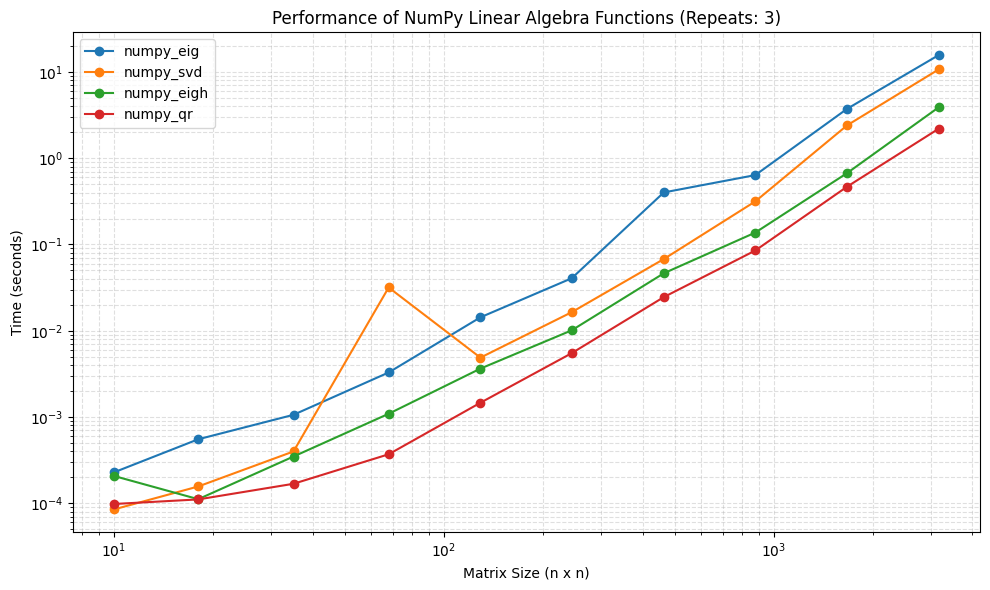

In [ ]:
# Sort timings by average time for better visualization
timings = dict(sorted(timings.items(), key=lambda item: np.mean(item[1]), reverse=True))

# Plotting the results
plt.figure(figsize=(10, 6))
for name, times in timings.items():
    plt.plot(matrix_sizes, times, marker="o", label=name)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Matrix Size (n x n)")
plt.ylabel("Time (seconds)")
plt.title(f"Performance of NumPy Linear Algebra Functions (Repeats: {repeats})")
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()